# بخش 6: تحلیل افق پیش بینی

In [5]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / 'src'))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import time
import matplotlib.pyplot as plt


from data_utils import load_synthetic_data, normalize_data, split_train_test
from plotting import save_figure, save_table



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)
data_path = None
input_features = ['x1', 'x2', 'x3', 'x4', 'x5']
target_feature = 'y'
batch_size = 64
hidden_size = 64
seq_length = 30
epochs = 50
learning_rate = 0.01
horizons = [1, 5, 10, 20, 50]



به جای پیش بینی یک گام بعد، اکنون پیش بینی چند گام بعد را به صورت بازگشتی (recursive) انجام دهید:

•	گام ‌های 1، 5، 10، 20 و 50.


معماری ‌های  RNN، LSTM  و GRU را با طول پنجره N = 30 و اندازه نهان 64 برای هر افق ارزیابی کنید. نمودار خطای MSE بر حسب افق پیش ‌بینی را رسم کنید.

الف) چرا با افزایش افق پیش‌بینی، خطا افزایش می‌یابد؟ مفاهیم compound error و error accumulation را توضیح دهید.

ب) کدام معماری بیشترین مقاومت را در برابر افزایش افق دارد؟ دلیل را با توجه به حافظه بلندمدت تحلیل کنید.

In [7]:
data = load_synthetic_data(data_path)
train_data, test_data = split_train_test(data, train_ratio=0.8)
train_norm, test_norm, stats = normalize_data(train_data, test_data)

def create_sequences(data, seq_len):
    """Create input-output pairs for supervised learning."""
    X_list, y_list = [], []
    features = np.column_stack([data[f] for f in input_features])
    target = data[target_feature]
    for i in range(len(data) - seq_len):
        X_list.append(features[i:i+seq_len])
        y_list.append(target[i+seq_len])
    return np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.float32)

X_train, y_train = create_sequences(train_norm, seq_length)
X_test, y_test = create_sequences(test_norm, seq_length)

# Create DataLoaders
train_dataset = torch.utils.data.TensorDataset(torch.tensor(X_train), torch.tensor(y_train))
test_dataset = torch.utils.data.TensorDataset(torch.tensor(X_test), torch.tensor(y_test))
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


In [8]:
class RNNModel(nn.Module):
    def __init__(self, input_size=5, hidden_size=64, output_size=1):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True, nonlinearity='tanh')
        self.fc = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :]).squeeze(-1)

class LSTMModel(nn.Module):
    def __init__(self, input_size=5, hidden_size=64, output_size=1):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :]).squeeze(-1)

class GRUModel(nn.Module):
    def __init__(self, input_size=5, hidden_size=64, output_size=1):
        super().__init__()
        self.gru = nn.GRU(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        out, _ = self.gru(x)
        return self.fc(out[:, -1, :]).squeeze(-1)


In [9]:
def train_model(model, train_loader, epochs=50, lr=0.01):
    model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    model.train()
    for epoch in range(epochs):
        total_loss = 0.0
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(Xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        if (epoch+1) % 10 == 0:
            print(f"{model.__class__.__name__:6s} Epoch {epoch+1}/{epochs} | Loss: {total_loss/len(train_loader):.6f}")
    return model


In [10]:
rnn_model = train_model(RNNModel(), train_loader, epochs, learning_rate)


RNNModel Epoch 10/50 | Loss: 0.418389
RNNModel Epoch 20/50 | Loss: 0.421182
RNNModel Epoch 30/50 | Loss: 0.436731
RNNModel Epoch 40/50 | Loss: 0.467124
RNNModel Epoch 50/50 | Loss: 0.450864


In [11]:

lstm_model = train_model(LSTMModel(), train_loader, epochs, learning_rate)


LSTMModel Epoch 10/50 | Loss: 0.397510
LSTMModel Epoch 20/50 | Loss: 0.397657
LSTMModel Epoch 30/50 | Loss: 0.397518
LSTMModel Epoch 40/50 | Loss: 0.397091
LSTMModel Epoch 50/50 | Loss: 0.395490


In [12]:
gru_model = train_model(GRUModel(), train_loader, epochs, learning_rate)

GRUModel Epoch 10/50 | Loss: 0.421660
GRUModel Epoch 20/50 | Loss: 0.408061
GRUModel Epoch 30/50 | Loss: 0.406272
GRUModel Epoch 40/50 | Loss: 0.402660
GRUModel Epoch 50/50 | Loss: 0.423378


In [13]:
def recursive_forecast(model, initial_window, steps_ahead):
    """
    initial_window: numpy array of shape (seq_length, input_features)
    returns: list of predictions (length steps_ahead)
    """
    model.eval()
    current_window = initial_window.copy()
    predictions = []
    with torch.no_grad():
        for _ in range(steps_ahead):
            inp = torch.tensor(current_window, dtype=torch.float32).unsqueeze(0).to(device)
            pred = model(inp).cpu().item()
            predictions.append(pred)
            # Update window: remove first step, append last known x (persistence)
            # Since we don't have future x's, we repeat the last observed x vector
            last_x = current_window[-1, :].copy()
            new_window = np.vstack([current_window[1:], last_x])
            current_window = new_window
    return predictions


In [16]:
def evaluate_horizons(model, X_test, y_test, horizons):
    n_samples = len(X_test)
    results = {h: [] for h in horizons}
    for i in range(n_samples):
        initial_window = X_test[i]                 # shape (seq_len, 5)
        true_future = y_test[i:i+max(horizons)]    # actual y values after the window
        if len(true_future) < max(horizons):
            continue
        preds = recursive_forecast(model, initial_window, max(horizons))
        for h in horizons:
            results[h].append((preds[h-1] - true_future[h-1])**2)
    mse = {h: np.mean(results[h]) for h in horizons}
    return mse


In [17]:

rnn_mse = evaluate_horizons(rnn_model, X_test, y_test, horizons)
lstm_mse = evaluate_horizons(lstm_model, X_test, y_test, horizons)
gru_mse = evaluate_horizons(gru_model, X_test, y_test, horizons)

print("Horizon |     RNN MSE |    LSTM MSE |     GRU MSE")
print("-" * 50)
for h in horizons:
    print(f"{h:7d} | {rnn_mse[h]:10.6f} | {lstm_mse[h]:10.6f} | {gru_mse[h]:10.6f}")

# Save results table
df_horizon = pd.DataFrame({
    'Horizon': horizons,
    'RNN_MSE': [rnn_mse[h] for h in horizons],
    'LSTM_MSE': [lstm_mse[h] for h in horizons],
    'GRU_MSE': [gru_mse[h] for h in horizons]
})
save_table(df_horizon, 'forecast_horizon_results')


Horizon |     RNN MSE |    LSTM MSE |     GRU MSE
--------------------------------------------------
      1 |   0.487257 |   0.394463 |   0.414821
      5 |   0.529227 |   0.456241 |   0.435540
     10 |   0.618247 |   0.588891 |   0.494437
     20 |   0.675171 |   0.679386 |   0.577118
     50 |   0.874366 |   0.949263 |   0.826448


,Horizon,RNN_MSE,LSTM_MSE,GRU_MSE
0,1,0.487257,0.394463,0.414821
1,5,0.529227,0.456241,0.435540
2,10,0.618247,0.588891,0.494437
3,20,0.675171,0.679386,0.577118
4,50,0.874366,0.949263,0.826448


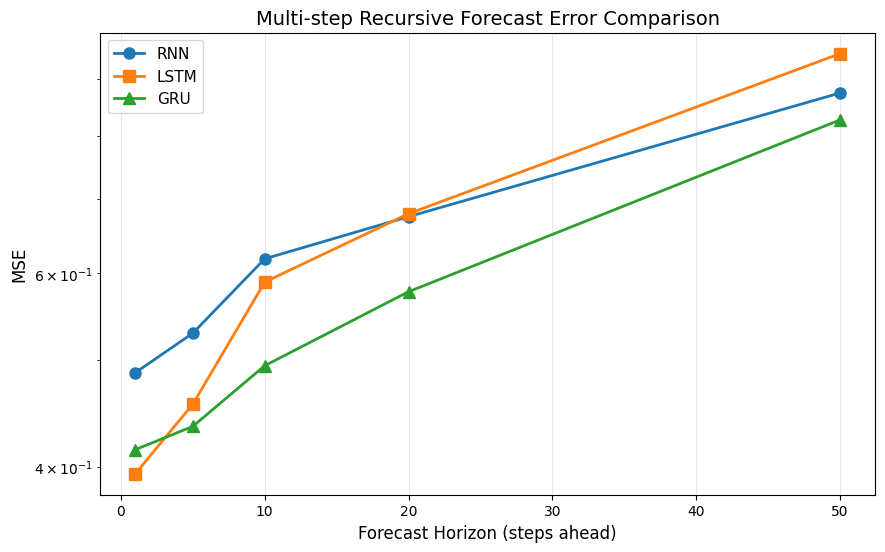

In [18]:

# ---------- Plot MSE vs Horizon ----------
plt.figure(figsize=(10, 6))
plt.plot(horizons, [rnn_mse[h] for h in horizons], 'o-', label='RNN', linewidth=2, markersize=8)
plt.plot(horizons, [lstm_mse[h] for h in horizons], 's-', label='LSTM', linewidth=2, markersize=8)
plt.plot(horizons, [gru_mse[h] for h in horizons], '^-', label='GRU', linewidth=2, markersize=8)
plt.xlabel('Forecast Horizon (steps ahead)', fontsize=12)
plt.ylabel('MSE', fontsize=12)
plt.title('Multi-step Recursive Forecast Error Comparison', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.show()
save_figure(plt.gcf(), 'forecast_horizon_comparison')
